<!--

    Gaia Data Processing and Analysis Consortium (DPAC) 
    Co-ordination Unit 9 Work Package 930, based on 
    original scripts provided by the Apache SW Foundation
    
    (c) 2005-2025 Gaia DPAC
    
    This program is free software: you can redistribute it and/or modify
    it under the terms of the GNU General Public License as published by
    the Free Software Foundation, either version 3 of the License, or
    (at your option) any later version.

    This program is distributed in the hope that it will be useful,
    but WITHOUT ANY WARRANTY; without even the implied warranty of
    MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
    GNU General Public License for more details.

    You should have received a copy of the GNU General Public License
    along with this program.  If not, see <https://www.gnu.org/licenses/>.
    -->
    
This notebook illustrates a few tips and tricks that should aid users in interacting with the platform via the Jupyter user interface.

Users should be aware that the platform accesses a shared compute cluster. Depending on activity elsewhere cell execution may result in "Pending" jobs and we kindly request that users be patient. 

If, however, a running notebook cell becomes unresponsive (e.g. goes away running and never comes back) or behaves in unexpected ways (the Python interpreter can get occasionally tied in knots) as a last resort you can reset using the "Restart the kernel" option available in the menu above (the circular arrow). Note that this will kill all currently executing jobs in your context and free up all memory so you must re-establish the platform set-up in the resulting fresh Dask Client:

    # Import the Dask client
    c = Client('tcp://simple-scheduler.dask-operator.svc.cluster.local:8786')

before doing anything else. This is why we recommend that you include this line at the top of each notebook workflow.

You can export data from, or import data to the platform via your Jupyter account home directory (by default `/home/jovyan/`), onto or from your local desktop. 

The easiest option is to find the data in the file explorer on your left (or click the file icon in the top left corner), and right-click on the files or directories you want to save, and select `Download`. Directories will be zipped for you. To import files, simply locate and click the `Upload Files` icon (upward pointing arrow) in the top left of the GUI.

To save in-memory data (for example as expressed in a results DataFrame) on the platform in a file for export, be aware that a Dask DataFrame is a distributed data set. If you save such an object to disk you will get a large set of partition files reflecting the natural distribution of the underlying source data. This is neither convenient nor particularly friendly. Provided the data size is not too large it is better to collect the distributed data to a non-distributed object on the master executor. The easiest way to do this is to call the `.compute()` method of the DataFrame, then this can be saved to a convenient format (e.g. comma-separated value).

In [ ]:
from dask.distributed import Client
import dask.dataframe as dd
import os
from pathlib import Path

In [ ]:
# simple example of saving a results file to disk, e.g. prior to transfer off the platform to a user's local file system (see final paragraph in the description in the cell above)

# standard set-up
c = Client('tcp://simple-scheduler.dask-operator.svc.cluster.local:8786')

# create an example data set
df = dd.read_parquet(Path(os.environ['DASK_DATA_PATH_GAIA_DR3_SSD']).joinpath("GDR3_GAIA_SOURCE")).sample(frac=1e-3) # take a small sample to keep example fast


/usr/local/lib/python3.10/site-packages/distributed/client.py:1612: VersionMismatchWarning: Mismatched versions found

+---------+-----------------+-----------------+-----------------+
| Package | Client          | Scheduler       | Workers         |
+---------+-----------------+-----------------+-----------------+
| lz4     | 4.4.4           | 4.3.3           | 4.3.3           |
| numpy   | 2.2.6           | 2.2.2           | 2.2.2           |
| python  | 3.10.16.final.0 | 3.10.12.final.0 | 3.10.12.final.0 |
| toolz   | 1.0.0           | 0.12.0          | 0.12.0          |
| tornado | 6.4.1           | 6.4.2           | 6.4.2           |
+---------+-----------------+-----------------+-----------------+
  warnings.warn(version_module.VersionMismatchWarning(msg[0]["warning"]))


In [3]:
# collect results to Pandas and save to csv in the user's home directory
df.compute().to_csv('/home/jovyan/astroflow-notebooks/dask/xp_sample.csv', index=False)

/usr/local/lib/python3.10/site-packages/distributed/client.py:3370: UserWarning: Sending large graph of size 15.11 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


## Visualisation options

One big advantage of notebooks is that you can visualise data with your within your code and mark-down cells. [Matplotlib](https://matplotlib.org) is the premier Python plotting module available on this platform and it works in much the same way as other familiar Python environments (but note that an explicit call to `show()` is not necessary - plot rendering is accomplished via a post-execute hook which tells Jupyter to plot all currently open matplotlib figures after executing the rest of the paragraph). Saving a plot locally is as simple as calling the pyplot instance savefig() method (see above for instructions on transfering files off the platform).



Text(0, 0.5, 'some numbers')

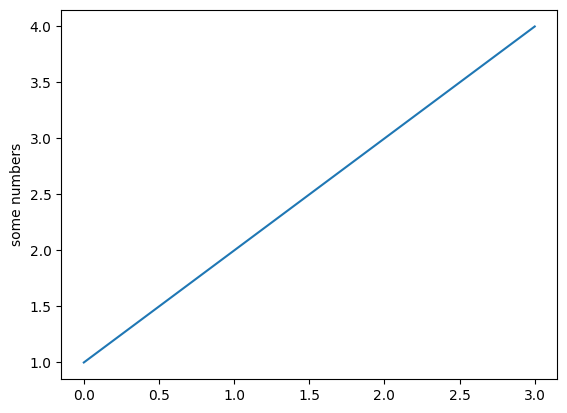

In [4]:
import matplotlib.pyplot as plt

plt.plot([1,2,3,4])
plt.ylabel('some numbers')

Pandas provides a high level API for visualisation of Pandas data frames. It uses matplotlib for its visualization under the hood, so the usage is the same as matplotlib. 

<Axes: >

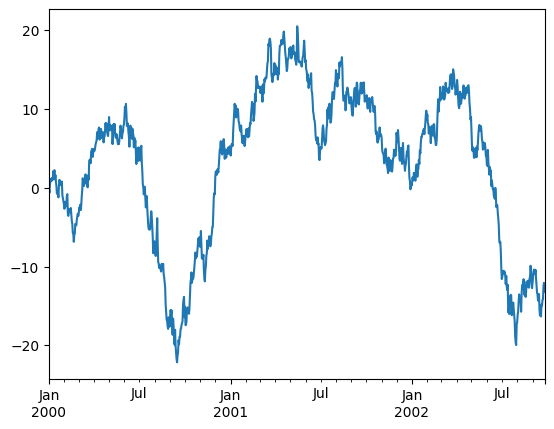

In [5]:
import pandas as pd
import numpy as np

ts = pd.Series(np.random.randn(1000), index=pd.date_range('1/1/2000', periods=1000))
ts = ts.cumsum()
ts.plot()